## Importing the relevant libraries

In [1]:
!pip install rouge-score textstat contractions

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.3/105.3 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 939.4/939.4 kB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.9/289.9 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.3/118.3 kB 9.6 MB/s eta 0:00:00
  Created wheel for rouge-score: filename=rouge_score-0.1.2-py3-none-any.whl size=24935 sha256=26a69bce450ca130663fb94ef2331b25c97e42c364c3834643006b4f028c74fd
  Stored in directory: /root/.cache/pip/wheels/1e/19/43/8a442dc83660ca25e163e1bd1f89919284ab0d0c1475475148
Successfully built rouge-score


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import nltk, warnings, contractions, re
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, Embedding, LSTM, Input, TimeDistributed, LayerNormalization, Attention, Concatenate
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, TensorBoard, ReduceLROnPlateau
from tensorflow.keras.utils import plot_model, to_categorical
from collections import Counter
from wordcloud import WordCloud
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from rouge_score import rouge_scorer
from tqdm.notebook import tqdm
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")
from textstat import flesch_reading_ease, flesch_kincaid_grade
from sklearn.metrics import jaccard_score
from sklearn.feature_extraction.text import TfidfVectorizer
tqdm.pandas()
from collections import Counter
from nltk.translate.bleu_score import corpus_bleu

2025-05-02 23:35:23.264465: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1746228923.465889      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1746228923.523348      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
nltk.download('omw-1.4')

[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...


True

## Loading the datasets

In [4]:
train_df = pd.read_csv('C:/Users/Piyush/Downloads/glove.6B.100d.txt')
train_df.head()

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com..."


In [5]:
val_df = pd.read_csv('C:/Users/Piyush/Downloads/glove.6B.100d.txt')
val_df.head()

,id,dialogue,summary
0,13817023,"A: Hi Tom, are you busy tomorrow’s afternoon?\...",A will go to the animal shelter tomorrow to ge...
1,13716628,Emma: I’ve just fallen in love with this adven...,Emma and Rob love the advent calendar. Lauren ...
2,13829420,Jackie: Madison is pregnant\r\nJackie: but she...,Madison is pregnant but she doesn't want to ta...
3,13819648,Marla: <file_photo>\r\nMarla: look what I foun...,Marla found a pair of boxers under her bed.
4,13728448,Robert: Hey give me the address of this music ...,Robert wants Fred to send him the address of t...


In [6]:
train_df.shape

(14732, 3)

In [7]:
train_df.isna().sum()

id          0
dialogue    1
summary     0
dtype: int64

In [8]:
train_df.duplicated().sum()

0

In [9]:
train_df = train_df.dropna()
train_df.shape

(14731, 3)

In [10]:
val_df.shape

(818, 3)

In [11]:
val_df.isna().sum()

id          0
dialogue    0
summary     0
dtype: int64

In [12]:
val_df.duplicated().sum()

0

In [13]:
test_df = pd.read_csv('C:/Users/Piyush/Downloads/glove.6B.100d.txt')
test_df.head()

,id,dialogue,summary
0,13862856,"Hannah: Hey, do you have Betty's number?\nAman...",Hannah needs Betty's number but Amanda doesn't...
1,13729565,Eric: MACHINE!\r\nRob: That's so gr8!\r\nEric:...,Eric and Rob are going to watch a stand-up on ...
2,13680171,"Lenny: Babe, can you help me with something?\r...",Lenny can't decide which trousers to buy. Bob ...
3,13729438,"Will: hey babe, what do you want for dinner to...",Emma will be home soon and she will let Will k...
4,13828600,"Ollie: Hi , are you in Warsaw\r\nJane: yes, ju...",Jane is in Warsaw. Ollie and Jane has a party....


In [14]:
test_df.shape

(819, 3)

In [15]:
test_df.isna().sum()

id          0
dialogue    0
summary     0
dtype: int64

In [16]:
test_df.duplicated().sum()

0

In [17]:
# Combine all datasets into one comprehensive dataset
df = pd.concat([train_df,val_df,test_df],axis=0)
df.head()

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com..."


## Data Exploration

In [18]:
df.shape

(16368, 3)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16368 entries, 0 to 818
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        16368 non-null  object
 1   dialogue  16368 non-null  object
 2   summary   16368 non-null  object
dtypes: object(3)
memory usage: 511.5+ KB


In [20]:
df.describe()

,id,dialogue,summary
count,16368,16368,16368
unique,16368,15809,16366
top,13818810,"Tim: Hi Bart, how are you?\r\nBart: I'm good, ...",Seth's pet Oreo that he got when he was 10 is ...
freq,1,4,2


In [21]:
df['dialogue_len'] = df.dialogue.apply(len)
df['summary_len'] = df.summary.apply(len)

In [22]:
df.describe()

,dialogue_len,summary_len
count,16368.000000,16368.000000
mean,511.146872,110.073130
std,402.996026,60.794659
min,31.000000,3.000000
25%,217.000000,63.000000
50%,400.000000,96.000000
75%,693.250000,144.000000
max,5492.000000,300.000000


## Exploratory Data Analysis (EDA)

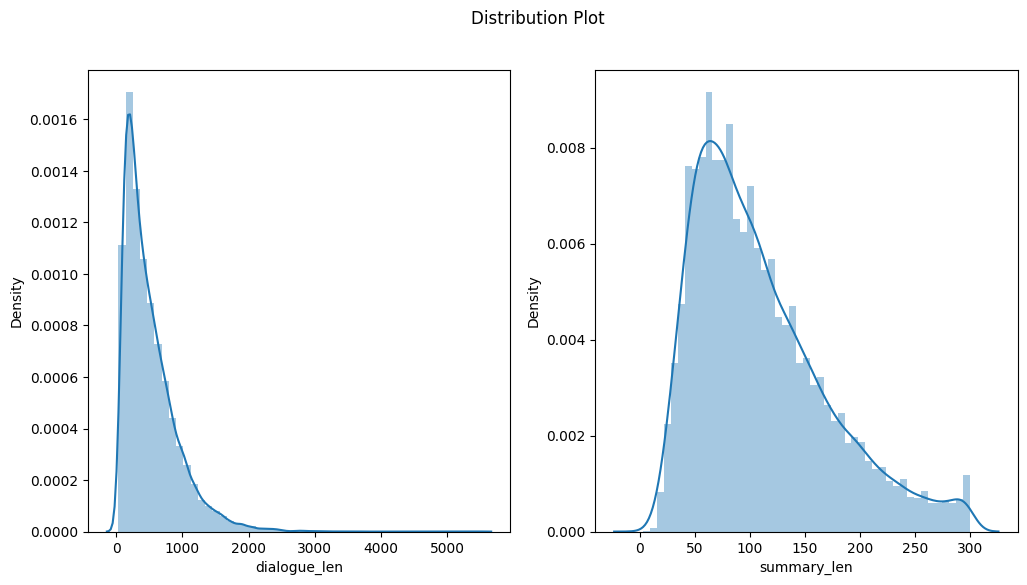

In [23]:
plt.figure(figsize=(12,6))
plt.subplot(121)
sns.distplot(df['dialogue_len'])
plt.subplot(122)
sns.distplot(df['summary_len'])
plt.suptitle('Distribution Plot')
plt.show();

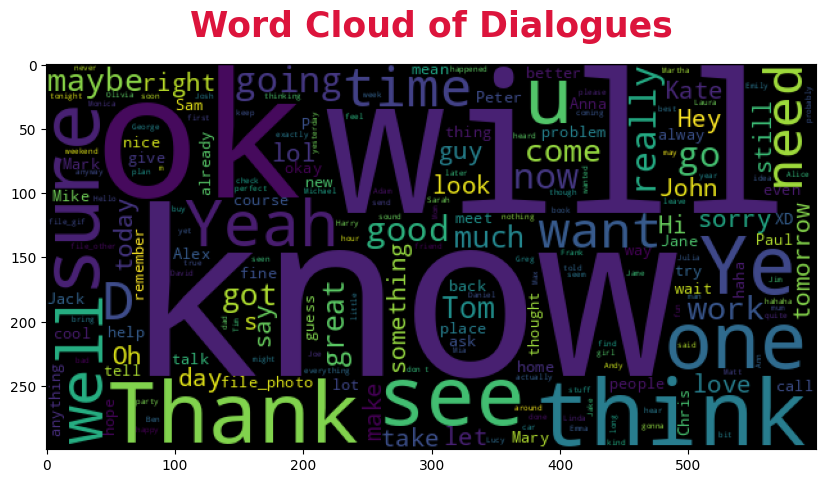

In [24]:
plt.figure(figsize=(12,5))
wc = WordCloud(width=600,height=300,random_state=42).generate(' '.join(df.dialogue))
plt.imshow(wc)
plt.title('Word Cloud of Dialogues',fontsize=25,pad=20,color='crimson',fontweight='bold')
plt.show();

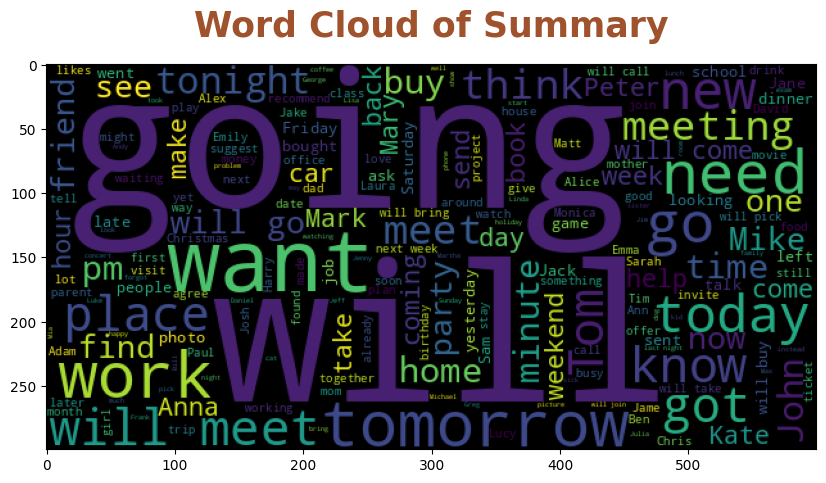

In [25]:
plt.figure(figsize=(12,5))
wc = WordCloud(width=600,height=300,random_state=42).generate(' '.join(df.summary))
plt.imshow(wc)
plt.title('Word Cloud of Summary',fontsize=25,pad=20,color='sienna',fontweight='bold')
plt.show();

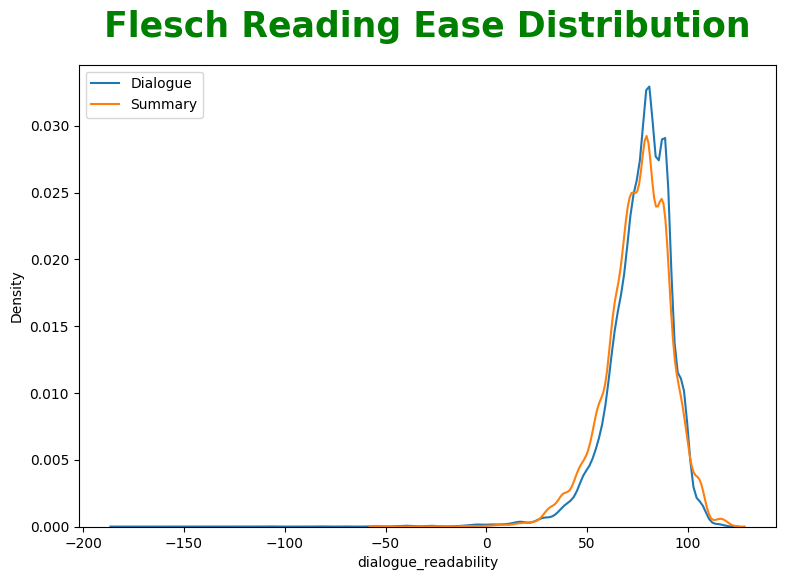

In [26]:
df['dialogue_readability'] = df['dialogue'].apply(flesch_reading_ease)
df['summary_readability'] = df['summary'].apply(flesch_reading_ease)

plt.figure(figsize=(9,6))
sns.kdeplot(df['dialogue_readability'], label='Dialogue')
sns.kdeplot(df['summary_readability'], label='Summary')
plt.title("Flesch Reading Ease Distribution",fontsize=25,pad=20,color='green',fontweight='bold')
plt.legend()
plt.show();

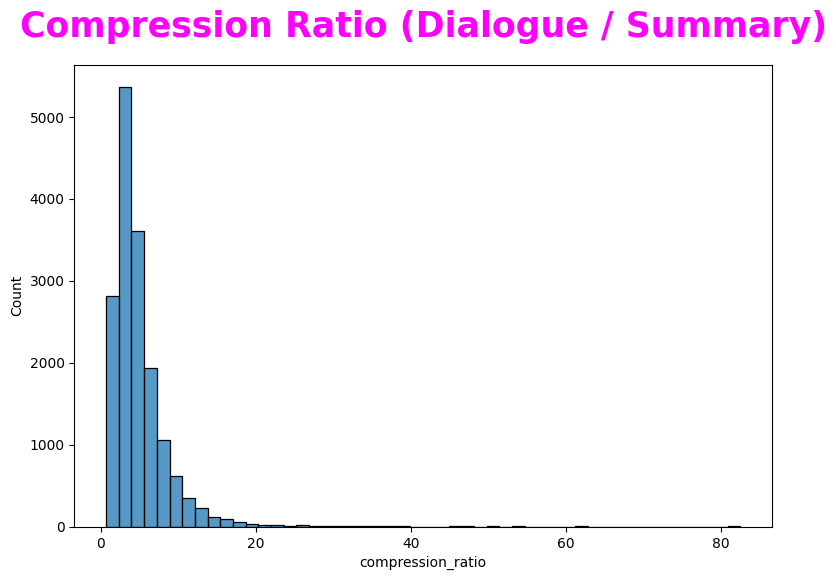

In [27]:
df['compression_ratio'] = df['dialogue_len'] / df['summary_len']
plt.figure(figsize=(9,6))
sns.histplot(df['compression_ratio'], bins=50)
plt.title("Compression Ratio (Dialogue / Summary)",fontsize=25,pad=20,color='fuchsia',fontweight='bold')
plt.show();

In [28]:
def jaccard_similarity(document,summary):
    doc_content = set(document.split())
    sum_content = set(summary.split())
    return len(doc_content & sum_content) / len(doc_content | sum_content)

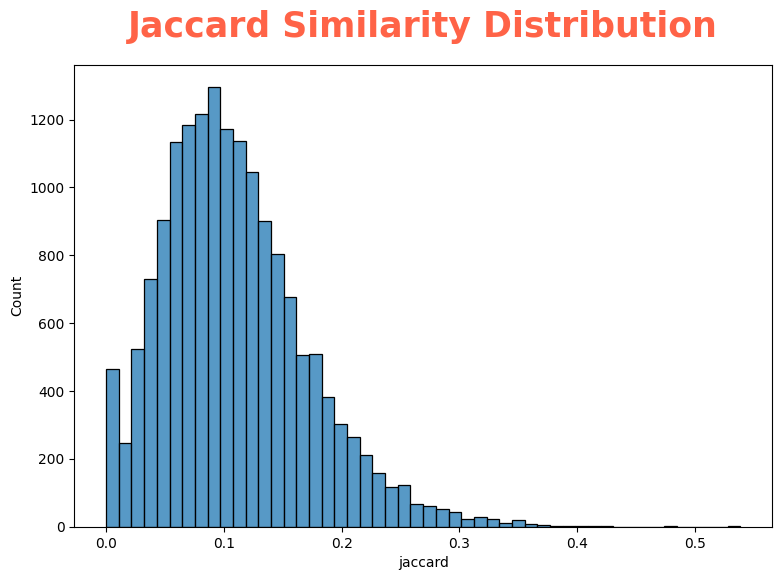

In [29]:
# Measure token overlap
df['jaccard'] = df.apply(lambda x: jaccard_similarity(x['dialogue'], x['summary']), axis=1)

plt.figure(figsize=(9,6))
sns.histplot(df['jaccard'], bins=50)
plt.title("Jaccard Similarity Distribution",fontsize=25,pad=20,color='tomato',fontweight='bold')
plt.show();

In [30]:
# TF-IDF keyword matching - Match key words in dialogue vs summary
tfidf = TfidfVectorizer(max_features=1000)
tfidf_dialogue = tfidf.fit_transform(df['dialogue']).toarray()
tfidf_summary = tfidf.transform(df['summary']).toarray()

keyword_overlap = (tfidf_dialogue * tfidf_summary).sum(axis=1)

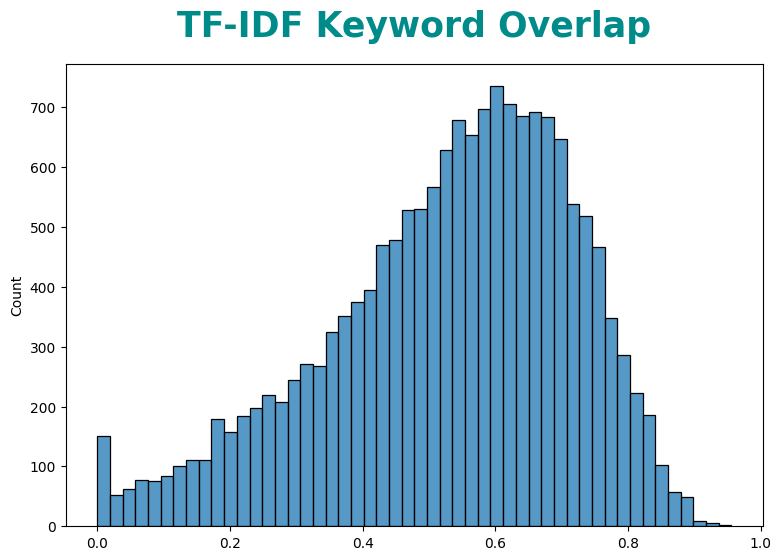

In [31]:
plt.figure(figsize=(9,6))
sns.histplot(keyword_overlap, bins=50, palette='viridis')
plt.title("TF-IDF Keyword Overlap",fontsize=25,pad=20,color='darkcyan',fontweight='bold')
plt.show();

In [32]:
def novelty_ratio(dialogue, summary):
    d = set(dialogue.split())
    s = set(summary.split())
    return len(s - d) / max(1, len(s))

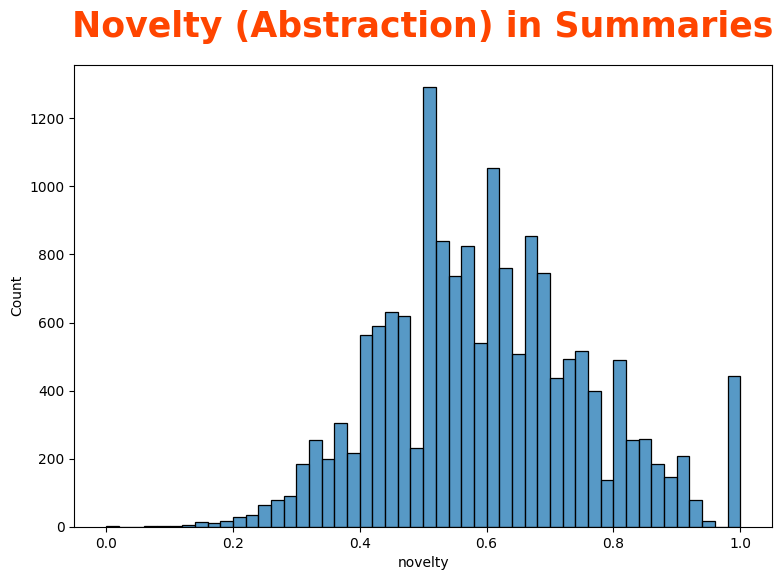

In [33]:
# Novelty ratio - Proportion of summary words not present in dialogue
df['novelty'] = df.apply(lambda x: novelty_ratio(x['dialogue'], x['summary']), axis=1)

plt.figure(figsize=(9,6))
sns.histplot(df['novelty'], bins=50, palette='coolwarm')
plt.title("Novelty (Abstraction) in Summaries",fontsize=25,pad=20,color='orangered',fontweight='bold')
plt.show();

## Text Preprocessing

In [34]:
def lowercase_text(text):
    return text.lower()

In [35]:
def remove_url(text):
    pattern = re.compile(r'https?://\S+|www\.\S+')
    return pattern.sub(r'',text)

In [36]:
def remove_html_tags(text):
    pattern = r'[^a-zA-Z0-9\s]'
    text = re.sub(pattern,'',text)
    return text

In [37]:
chat_words = {
    "AFAIK": "As Far As I Know",
    "AFK": "Away From Keyboard",
    "ASAP": "As Soon As Possible",
    "ATK": "At The Keyboard",
    "ATM": "At The Moment",
    "A3": "Anytime, Anywhere, Anyplace",
    "BAK": "Back At Keyboard",
    "BBL": "Be Back Later",
    "BBS": "Be Back Soon",
    "BFN": "Bye For Now",
    "B4N": "Bye For Now",
    "BRB": "Be Right Back",
    "BRT": "Be Right There",
    "BTW": "By The Way",
    "B4": "Before",
    "CU": "See You",
    "CUL8R": "See You Later",
    "CYA": "See You",
    "FAQ": "Frequently Asked Questions",
    "FC": "Fingers Crossed",
    "FWIW": "For What It's Worth",
    "FYI": "For Your Information",
    "GAL": "Get A Life",
    "GG": "Good Game",
    "GN": "Good Night",
    "GMTA": "Great Minds Think Alike",
    "GR8": "Great!",
    "G9": "Genius",
    "IC": "I See",
    "ICQ": "I Seek you (also a chat program)",
    "ILU": "I Love You",
    "IMHO": "In My Honest/Humble Opinion",
    "IMO": "In My Opinion",
    "IOW": "In Other Words",
    "IRL": "In Real Life",
    "KISS": "Keep It Simple, Stupid",
    "LDR": "Long Distance Relationship",
    "LMAO": "Laugh My A.. Off",
    "LOL": "Laughing Out Loud",
    "LTNS": "Long Time No See",
    "L8R": "Later",
    "MTE": "My Thoughts Exactly",
    "M8": "Mate",
    "NRN": "No Reply Necessary",
    "OIC": "Oh I See",
    "PITA": "Pain In The A..",
    "PRT": "Party",
    "PRW": "Parents Are Watching",
    "QPSA": "Que Pasa?",
    "ROFL": "Rolling On The Floor Laughing",
    "ROFLOL": "Rolling On The Floor Laughing Out Loud",
    "ROTFLMAO": "Rolling On The Floor Laughing My A.. Off",
    "SK8": "Skate",
    "STATS": "Your sex and age",
    "ASL": "Age, Sex, Location",
    "THX": "Thank You",
    "TTFN": "Ta-Ta For Now!",
    "TTYL": "Talk To You Later",
    "U": "You",
    "U2": "You Too",
    "U4E": "Yours For Ever",
    "WB": "Welcome Back",
    "WTF": "What The F...",
    "WTG": "Way To Go!",
    "WUF": "Where Are You From?",
    "W8": "Wait...",
    "7K": "Sick:-D Laughter",
    "TFW": "That feeling when",
    "MFW": "My face when",
    "MRW": "My reaction when",
    "IFYP": "I feel your pain",
    "LOL": "Laughing out loud",
    "TNTL": "Trying not to laugh",
    "JK": "Just kidding",
    "IDC": "I don’t care",
    "ILY": "I love you",
    "IMU": "I miss you",
    "ADIH": "Another day in hell",
    "IDC": "I don’t care",
    "ZZZ": "Sleeping, bored, tired",
    "WYWH": "Wish you were here",
    "TIME": "Tears in my eyes",
    "BAE": "Before anyone else",
    "FIMH": "Forever in my heart",
    "BSAAW": "Big smile and a wink",
    "BWL": "Bursting with laughter",
    "LMAO": "Laughing my a** off",
    "BFF": "Best friends forever",
    "CSL": "Can’t stop laughing",
}

In [38]:
def chat_conversion(text):
    new_text=[]
    for w in text.split():
        if w.upper() in chat_words:
            new_text.append(chat_words[w.upper()])
        else:
            new_text.append(w)
    return " ".join(new_text)

In [39]:
def remove_emoji(text):
    emoji_pattern = re.compile("["
                           u"\U0001F600-\U0001F64F"  # emoticons
                           u"\U0001F300-\U0001F5FF"  # symbols & pictographs
                           u"\U0001F680-\U0001F6FF"  # transport & map symbols
                           u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                           u"\U00002702-\U000027B0"
                           u"\U000024C2-\U0001F251"
                           "]+", flags=re.UNICODE)
    return emoji_pattern.sub(r'', text)

In [40]:
def expand_contractions(text):
    expanded_text = contractions.fix(text)
    return expanded_text

In [41]:
df.dialogue = df.dialogue.progress_apply(chat_conversion)
df.dialogue = df.dialogue.progress_apply(lowercase_text)
df.dialogue = df.dialogue.progress_apply(remove_url)
df.dialogue = df.dialogue.progress_apply(remove_html_tags)
df.dialogue = df.dialogue.progress_apply(remove_emoji)
df.dialogue = df.dialogue.progress_apply(expand_contractions)

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

In [42]:
df.summary = df.summary.progress_apply(chat_conversion)
df.summary = df.summary.progress_apply(lowercase_text)
df.summary = df.summary.progress_apply(remove_url)
df.summary = df.summary.progress_apply(remove_html_tags)
df.summary = df.summary.progress_apply(remove_emoji)
df.summary = df.summary.progress_apply(expand_contractions)

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

  0%|          | 0/16368 [00:00<?, ?it/s]

In [43]:
df['summary'] = df['summary'].apply(lambda x: '<sos> ' + x.strip() + ' <eos>')

In [44]:
MAX_VOCAB_SIZE = 24000

In [45]:
def get_tokenizer(text):
    tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)
    tokenizer.fit_on_texts(text)
    return tokenizer

In [46]:
def get_max_sentence_length(sentences):
    return max([len(line.split()) for line in sentences])

In [47]:
dialogue_tokenizer = get_tokenizer(df.dialogue)
max_dialogue_sent_len = get_max_sentence_length(df.dialogue.tolist())
dialogue_vocab_size = len(dialogue_tokenizer.word_index) + 1
print("Dialogue vocabulary size:", dialogue_vocab_size)
print("Maximum length of dialogue sentences:", max_dialogue_sent_len)

Dialogue vocabulary size: 33102
Maximum length of dialogue sentences: 819


In [48]:
summary_tokenizer = get_tokenizer(df.summary)
max_summary_sent_len = get_max_sentence_length(df.summary.tolist())
summary_vocab_size = len(summary_tokenizer.word_index) + 1
print("Summary vocabulary size:", summary_vocab_size)
print("Maximum length of summary sentences:", max_summary_sent_len)

Summary vocabulary size: 18558
Maximum length of summary sentences: 67


In [49]:
tokenizer = get_tokenizer(df.dialogue.tolist() + df.summary.tolist())
len(tokenizer.word_index)

35134

In [50]:
tokenizer.document_count

32736

In [51]:
df['dialogue'] = tokenizer.texts_to_sequences(df['dialogue'])
df['summary'] = tokenizer.texts_to_sequences(df['summary'])

In [52]:
for num in df['dialogue'].iloc[23]:
    word = tokenizer.index_word.get(num, 'UNK')  
    print(word, end=' ')

renee just saying hi thought of you this morninglayla misses you she is having knee surgery hope you are doing well rachel renee hey whoa so crazy that you wrote i was literally thinking of you the other day as well rachel i am doing really well getting settled here and everything looking for a new job rachel layla is getting knew surgery what happened renee her arthritis got really bad i saw her limping every tears in my eyes we went out for a walk and so i took her to the vet and they decided she needs surgery rachel oh wow that is really intense i am sending her lots of love renee thanks rachel renee here is a pic of layla from this morning renee filepicture renee she is all cute in her usual spot rachel ha yeah i remember she would always try to fit in there even though she is obviously too big rachel renee yeah she is always getting into some sort of silly situations renee what kind of work are you looking for rachel just the usual something with teaching i am not too stressed yet

In [53]:
for num in df['summary'].iloc[23]:
    word = tokenizer.index_word.get(num, 'UNK')  
    print(word, end=' ')

sos layla the dog misses rachel she is having a knee surgery because of arthritis renee sends a picture of her dog rachel getting settled and she is looking for a job in teaching eos 

In [54]:
max_dialogue_len = 300
max_summary_len = 50

In [55]:
X = pad_sequences(df['dialogue'],max_dialogue_len,padding='post',truncating='post')
y = pad_sequences(df['summary'],max_summary_len,padding='post',truncating='post')

In [56]:
X.shape, y.shape

((16368, 300), (16368, 50))

## Performing train test split

In [57]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=42)

In [58]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((11457, 300), (4911, 300), (11457, 50), (4911, 50))

## Defining the model architecture

In [59]:
def build_seq2seq_lstm_attention_model(src_vocab_size, dest_vocab_size, embedding_dim, units, src_timesteps, dest_timesteps):
    """
    LSTM seq2seq model with attention for text summarization.
    """
    # Encoder
    encoder_inputs = Input(shape=(src_timesteps,),name='encoder_inputs')
    encoder_embeddings = Embedding(input_dim=src_vocab_size,output_dim=embedding_dim,name='encoder_embeddings')(encoder_inputs)

    encoder_lstm = LSTM(units=units,return_sequences=True,return_state=True,dropout=0.2,recurrent_dropout=0.1,name='encoder_lstm')
    encoder_outputs, encoder_state_h, encoder_state_c = encoder_lstm(encoder_embeddings)

    encoder_states = [encoder_state_h, encoder_state_c]
    
    # Decoder
    decoder_inputs = Input(shape=(dest_timesteps,), name='decoder_inputs')
    decoder_embeddings = Embedding(input_dim=dest_vocab_size, output_dim=embedding_dim, name='decoder_embeddings')(decoder_inputs)
    
    decoder_lstm = LSTM(units=units, return_sequences=True, return_state=True,dropout=0.3, recurrent_dropout=0.2, name='decoder_lstm')
    decoder_outputs, _, _ = decoder_lstm(decoder_embeddings, initial_state=encoder_states)
    
    # Attention layer
    context_vector = Attention(name='attention_layer')([decoder_outputs,encoder_outputs])
    
    # Combine context vector with decoder outputs
    decoder_combined_context = Concatenate(axis=-1,name='context_combined')([decoder_outputs,context_vector])
    decoder_combined_context = LayerNormalization()(decoder_combined_context)

    # Output layer
    decoder_dense = Dense(dest_vocab_size, activation='softmax')
    decoder_outputs = decoder_dense(decoder_combined_context)

    # Final model
    model = Model(inputs=[encoder_inputs,decoder_inputs],outputs=decoder_outputs)
    return model

In [60]:
# After loading embedding matrices
dialogue_vocab_size = len(tokenizer.word_index) + 1
summary_vocab_size = len(tokenizer.word_index) + 1
dialogue_max_len = X_train.shape[1]
summary_max_len = y_train.shape[1]
dialogue_vocab_size, summary_vocab_size, dialogue_max_len, summary_max_len

(35135, 35135, 300, 50)

In [61]:
model = build_seq2seq_lstm_attention_model(
    src_vocab_size=MAX_VOCAB_SIZE,
    dest_vocab_size=MAX_VOCAB_SIZE,
    embedding_dim=300,
    units=64,
    src_timesteps=max_dialogue_len,
    dest_timesteps=max_summary_len
)
model.summary()

I0000 00:00:1746228959.285892      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs            │ (None, 300)            │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ decoder_inputs            │ (None, 50)             │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ encoder_embeddings        │ (None, 300, 300)       │      7,200,000 │ encoder_inputs[0][0]   │
│ (Embedding)               │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ decoder_embeddings        │ (None, 50, 300)        │      7,200,000 │ decoder_inputs[0][0]   │
│ (Embedding)               │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ encoder_lstm (LSTM)       │ [(None, 300, 64),      │         93,440 │ encoder_embeddings[0]… │
│                           │ (None, 64), (None,     │                │                        │
│                           │ 64)]                   │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ decoder_lstm (LSTM)       │ [(None, 50, 64),       │         93,440 │ decoder_embeddings[0]… │
│                           │ (None, 64), (None,     │                │ encoder_lstm[0][1],    │
│                           │ 64)]                   │                │ encoder_lstm[0][2]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ attention_layer           │ (None, 50, 64)         │              0 │ decoder_lstm[0][0],    │
│ (Attention)               │                        │                │ encoder_lstm[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ context_combined          │ (None, 50, 128)        │              0 │ decoder_lstm[0][0],    │
│ (Concatenate)             │                        │                │ attention_layer[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ layer_normalization       │ (None, 50, 128)        │            256 │ context_combined[0][0] │
│ (LayerNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)             │ (None, 50, 24000)      │      3,096,000 │ layer_normalization[0… │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 17,683,136 (67.46 MB)

 Trainable params: 17,683,136 (67.46 MB)

 Non-trainable params: 0 (0.00 B)

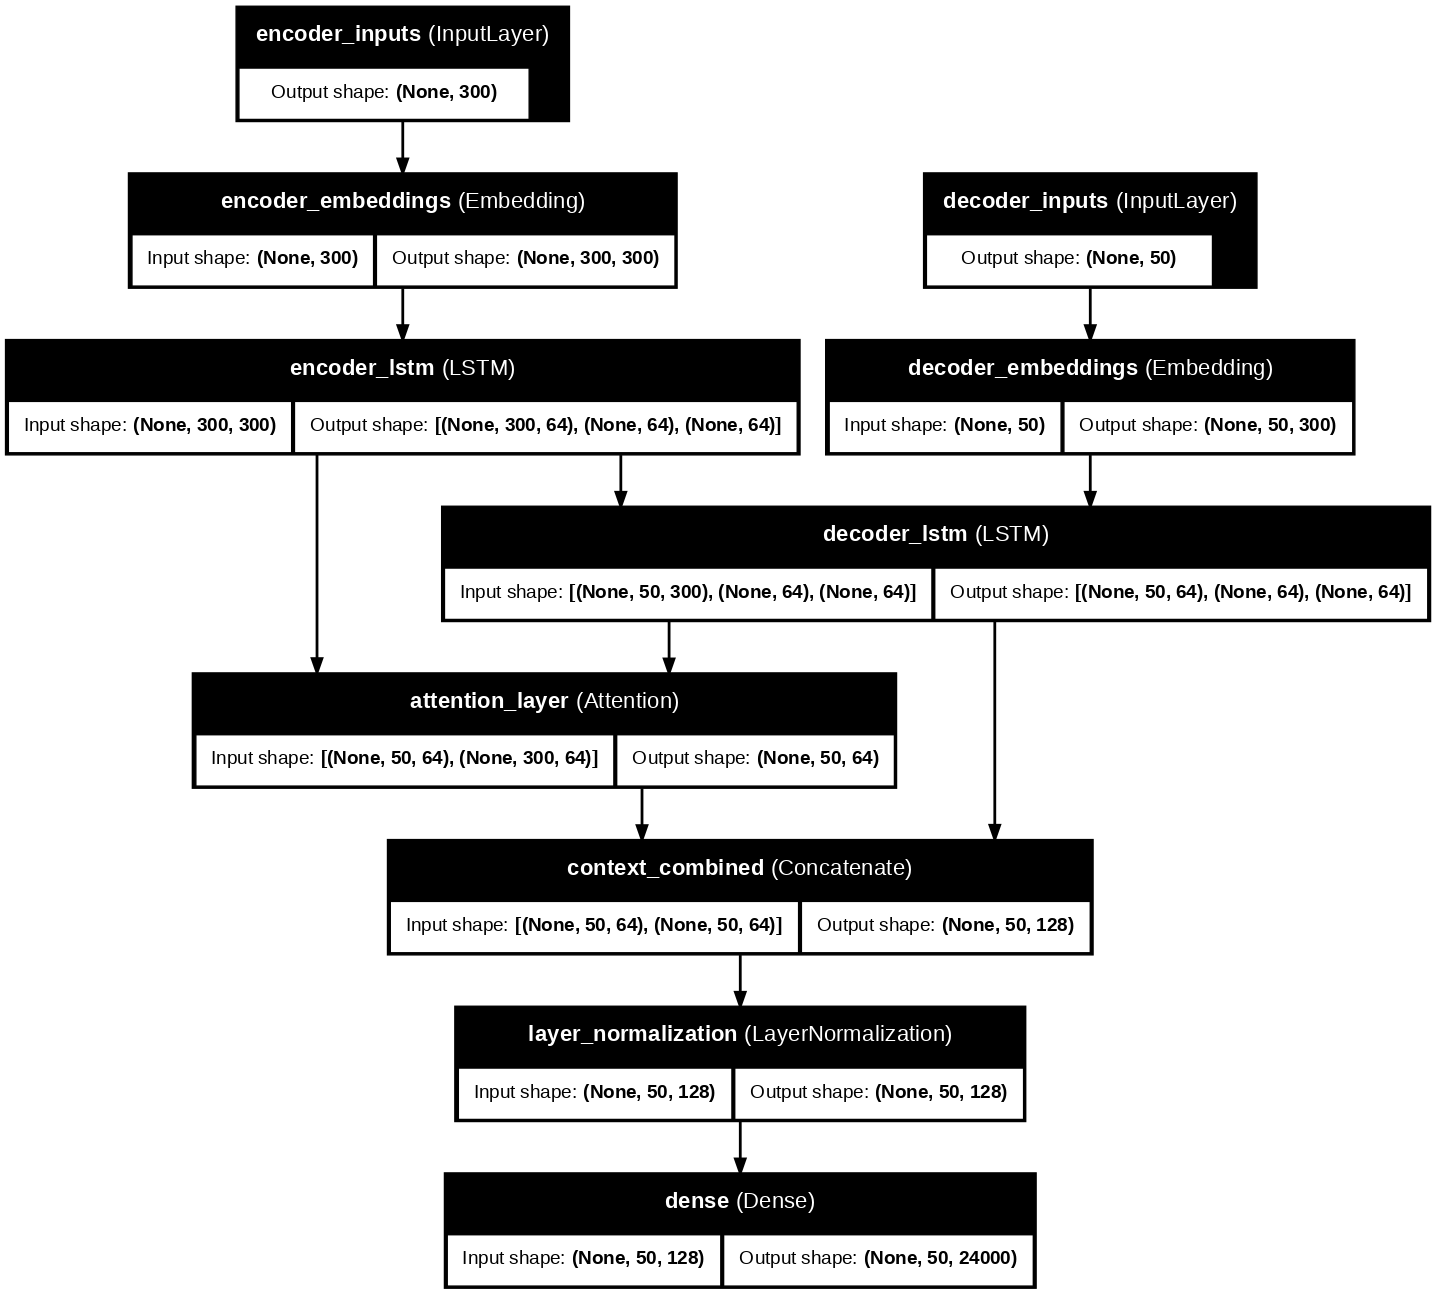

In [62]:
plot_model(model,'model.png',dpi=100,show_shapes=True,show_layer_names=True)

## Model Training & Evaluation

In [63]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [64]:
callbacks = [
    EarlyStopping(monitor='val_loss',patience=20,mode='min',restore_best_weights=True,verbose=1,start_from_epoch=3),
    ReduceLROnPlateau(monitor='val_loss',factor=0.1,patience=10,min_lr=1e-6,mode='min',verbose=1),
    TensorBoard(log_dir='./',histogram_freq=1,write_graph=True,update_freq='epoch',embeddings_freq=1),
    ModelCheckpoint(filepath='samsum_dialogues_text_summarizer.keras',monitor='val_loss',verbose=1,mode='min',save_best_only=True,save_freq='epoch')
]

r = model.fit(
    [X_train,y_train],
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=([X_test,y_test],y_test),
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 0s 527ms/step - accuracy: 0.5265 - loss: 5.6066
Epoch 1: val_loss improved from inf to 1.81034, saving model to samsum_dialogues_text_summarizer.keras
180/180 ━━━━━━━━━━━━━━━━━━━━ 125s 632ms/step - accuracy: 0.5270 - loss: 5.5956 - val_accuracy: 0.7798 - val_loss: 1.8103 - learning_rate: 0.0010
Epoch 2/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.8173 - loss: 1.4965
Epoch 2: val_loss improved from 1.81034 to 0.83356, saving model to samsum_dialogues_text_summarizer.keras
180/180 ━━━━━━━━━━━━━━━━━━━━ 113s 627ms/step - accuracy: 0.8175 - loss: 1.4953 - val_accuracy: 0.9079 - val_loss: 0.8336 - learning_rate: 0.0010
Epoch 3/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.9186 - loss: 0.7045
Epoch 3: val_loss improved from 0.83356 to 0.49054, saving model to samsum_dialogues_text_summarizer.keras
180/180 ━━━━━━━━━━━━━━━━━━━━ 113s 626ms/step - accuracy: 0.9187 - loss: 0.7041 - val_accuracy: 0.9493 - val_loss: 0.4905 - learni

## Model Performance Visualization

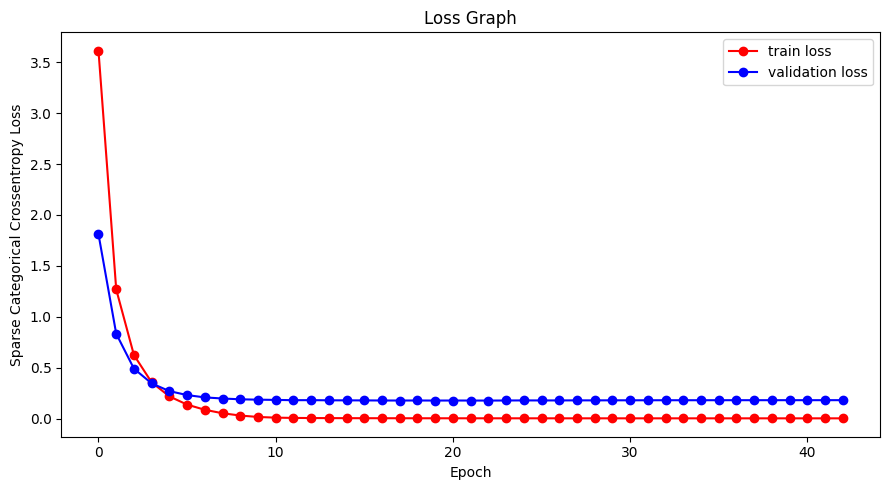

In [65]:
plt.figure(figsize=(9,5))
plt.plot(r.history['loss'],'r',label='train loss',marker='o')
plt.plot(r.history['val_loss'],'b',label='validation loss',marker='o')
plt.xlabel('Epoch')
plt.ylabel('Sparse Categorical Crossentropy Loss')
plt.title('Loss Graph')
plt.legend()
plt.tight_layout()
plt.show();

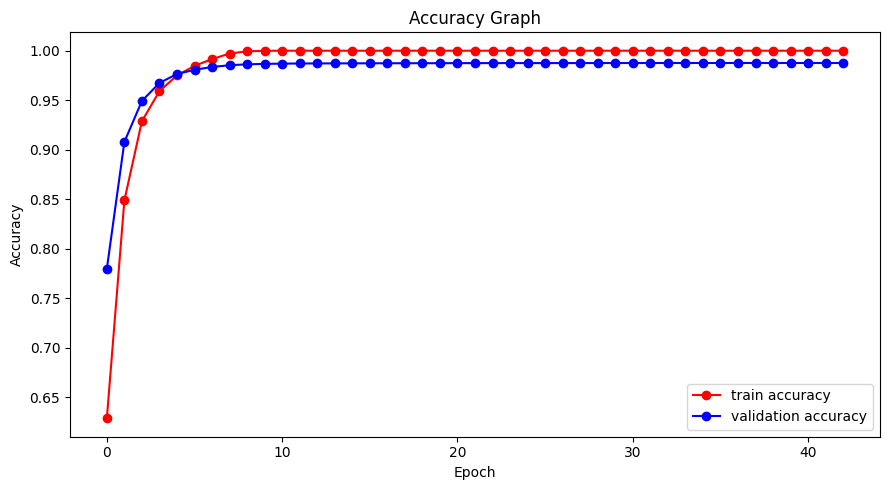

In [66]:
plt.figure(figsize=(9,5))
plt.plot(r.history['accuracy'],'r',label='train accuracy',marker='o')
plt.plot(r.history['val_accuracy'],'b',label='validation accuracy',marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Graph')
plt.legend()
plt.tight_layout()
plt.show();

## Model Inference

In [67]:
def summarize_model_predictions(model, tokenizer, X_test, y_test, num_samples=10):
    """
    Displays predicted vs actual summaries for a few test samples.
    
    Parameters:
    - model: Trained seq2seq model
    - tokenizer: Tokenizer used for both input and output
    - X_test: Padded input dialogues
    - y_test: Padded output summaries
    - num_samples: Number of examples to display
    """
    index_to_word = {idx: word for word, idx in tokenizer.word_index.items()}
    sos_idx = tokenizer.word_index.get('sos')
    eos_idx = tokenizer.word_index.get('eos')

    X_subset = X_test[:num_samples]
    y_subset = y_test[:num_samples]

    # Predict token probabilities
    predictions = model.predict([X_subset, y_subset], verbose=0, batch_size=64)
    predicted_token_ids = np.argmax(predictions, axis=-1)

    predicted_sentences = []
    actual_summaries = []
    dialogues = []

    for i in range(num_samples):
        # Convert predicted token ids to words
        pred_sentence = ' '.join([
            index_to_word.get(tok, '<unk>')
            for tok in predicted_token_ids[i]
            if tok != 0 and tok != sos_idx and tok != eos_idx
        ])
        predicted_sentences.append(pred_sentence)

        # Convert actual summary token ids to words
        actual_sentence = ' '.join([
            index_to_word.get(tok, '<unk>')
            for tok in y_subset[i]
            if tok != 0 and tok != sos_idx and tok != eos_idx
        ])
        actual_summaries.append(actual_sentence)

        # Convert input dialogue token ids to words
        input_dialogue = ' '.join([
            index_to_word.get(tok, '<unk>')
            for tok in X_subset[i]
            if tok != 0
        ])
        dialogues.append(input_dialogue)

    # Display results
    for i in range(num_samples):
        print(f"\n🗣️ Dialogue {i+1}:\n{dialogues[i]}")
        print(f"\n✅ Actual Summary:\n{actual_summaries[i]}")
        print(f"\n🔁 Predicted Summary:\n{predicted_sentences[i]}")
        print("-" * 100)

In [68]:
summarize_model_predictions(model, tokenizer, X_test, y_test, num_samples=10)


🗣️ Dialogue 1:
adam hey nina how are you what is up nina i am fine brother just feeding peter how are you and all adam we are all good i know the pain feeding them and putting them to sleep is the most difficult thing in the world nina i know right adam nine me and jill are planning a get to gather this sunday would you be able to join us all for lunch nina yes sure why not its been quiet long we have not had a family get to gather so nice of you and jill adam that is great yeah we needed it big tears in my eyes waiting to see you than nina thank you brother see ya

✅ Actual Summary:
nina is taking care of peter nina will join adam and jill for lunch on sunday

🔁 Predicted Summary:
nina is taking care of peter nina will join adam and jill for lunch on sunday
----------------------------------------------------------------------------------------------------

🗣️ Dialogue 2:
bob hey pick up your phone sam cannot i am on a date in a theater bob yeah right like you would get a date looser

In [69]:
rev_tok_summary = {idx: word for word, idx in tokenizer.word_index.items()}
rev_tok_dialogue = {idx: word for word, idx in tokenizer.word_index.items()} 

batch_size = 16

predicted_summaries = []
reference_summaries = []

# Predict on x_test data in batches
for start in range(0, len(X_test), batch_size):
    end = min(start + batch_size, len(X_test))
    X_batch = X_test[start:end]
    y_batch = y_test[start:end]  

    # Predict on the batch
    predictions = model.predict([X_batch, y_batch], batch_size=batch_size, verbose=0)
    
    # Convert predicted tokens to sentences (predicted summaries)
    predicted_tokens = np.argmax(predictions, axis=-1)

    for token_list in predicted_tokens:
        # Convert the predicted tokens into the corresponding words for the summary
        predicted_summary = ' '.join([rev_tok_summary.get(token, '<unknown>') for token in token_list if token != 0 and token not in [tokenizer.word_index.get('sos'), tokenizer.word_index.get('eos')]])
        predicted_summaries.append(predicted_summary)

    for i in range(len(y_batch)):
        original_summary = ' '.join([rev_tok_summary.get(token, '<unknown>') for token in y_batch[i] if token != 0 and token not in [tokenizer.word_index.get('sos'), tokenizer.word_index.get('eos')]])
        reference_summaries.append([original_summary.split()]) 

In [70]:
# Evaluate BLEU score for the predicted summaries
bleu_score = corpus_bleu(reference_summaries, [summary.split() for summary in predicted_summaries])
print(f'BLEU score: {bleu_score:.4f}')

BLEU score: 0.9299


In [71]:
def evaluate_rouge_scores(predicted_summaries, reference_summaries):
    """
    Evaluates ROUGE-1, ROUGE-2, and ROUGE-L scores for the predicted summaries.

    Parameters:
    - predicted_summaries: list of predicted summary strings
    - reference_summaries: list of list of reference summary strings (single reference per prediction)

    Returns:
    - Dictionary of average ROUGE scores
    """
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
    rouge1_scores, rouge2_scores, rougeL_scores = [], [], []

    for pred, ref_list in zip(predicted_summaries, reference_summaries):
        ref = ' '.join(ref_list[0])  # Since there's only one reference per prediction
        scores = scorer.score(ref, pred)

        rouge1_scores.append(scores['rouge1'].fmeasure)
        rouge2_scores.append(scores['rouge2'].fmeasure)
        rougeL_scores.append(scores['rougeL'].fmeasure)

    return {
        'ROUGE-1': np.mean(rouge1_scores),
        'ROUGE-2': np.mean(rouge2_scores),
        'ROUGE-L': np.mean(rougeL_scores)
    }

In [72]:
rouge_results = evaluate_rouge_scores(predicted_summaries, reference_summaries)

print("\n📊 ROUGE Scores:")
for metric, score in rouge_results.items():
    print(f"{metric}: {score:.4f}")


📊 ROUGE Scores:
ROUGE-1: 0.9689
ROUGE-2: 0.9430
ROUGE-L: 0.9689
